[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/Kiwi-challenge/notebooks/02-kiwi-digital-twin-and-inverse-problems.ipynb)

# The Computational Kiwi Challenge (Part 2): Polyploid Stability, 3D Point Processes, Inverse Problems & a Bloch-MRI Digital Twin

**BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Lab 5, Spring 2027)**  
*Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Lab 4 (Imaging) $\leftrightarrow$ Lab 5 (Computational Modeling) Sequence:**
> 0. [`00-kiwi-math-primer-for-biomedicine.ipynb`](./00-kiwi-math-primer-for-biomedicine.ipynb) — **Visual Math Primer ("Rosetta Stone"):** Friendly, intuition-first visual explanations of every symbol and mathematical tool (`ODEs`, $\nabla^2$, Turing stability, `CSR` vs. hard-core $G(r)$, Tikhonov $\lambda$, Rician noise) for biomedicine students & clinicians.
> 0a. [`00a-kiwi-anatomical-and-physiological-atlas.ipynb`](./00a-kiwi-anatomical-and-physiological-atlas.ipynb) — **Multi-Scale Anatomical & Physiological Atlas:** Macroscopic optical vs. 7T MRI contrast inversion, $\mu\text{m}$-scale histology, dioecious `XY` flowers, `BBCH` life cycle, & physiology.
> 1. [`01-kiwi-growth-and-morphogenesis.ipynb`](./01-kiwi-growth-and-morphogenesis.ipynb) — Progressive forward modeling from **Algebraic Saturation $\to$ Sex-Switch & Biophysical ODEs $\to$ 1D Ring Turing & 2D Paracrine PDEs**, tested on our 2005 7T MRI.
> 2. **`02-kiwi-digital-twin-and-inverse-problems.ipynb` (this notebook)** — Four graduate-level quantitative frameworks (**Spectral Turing Stability, 3D Spatial Point Processes, Ill-Posed PDE Inverse Problems & a Generative 3D Bloch-MRI Digital Twin**) closing the loop back to **[Lab 4 (`Lab4-Comp-Imag/Kiwi-challenge`)](../../../Lab4-Comp-Imag/Kiwi-challenge/README.md)**.

---

## 1. Motivation, Learning Outcomes & Quantitative Glossary

In **Part 1 (`01`)**, we built forward mechanistic models (Algebra $\to$ ODEs $\to$ PDEs) and verified their predictions on our 2005 7T MRI scan. In biomedical research, however, running a forward simulation once is only the beginning. MSc and PhD researchers routinely face four deeper questions:

1. **Analytical Predictability:** *Can we predict how genetic or geometric scaling (such as genome polyploidization or embryonic limb-bud widening) shifts organ pattern counts without running thousands of PDE simulations?*
2. **Spatial Hypothesis Testing:** *Are discrete biological objects in 3D microscopy or MRI (seeds, cell nuclei, infiltrating `CD8+` T cells) scattered at random, clustered, or mutually repulsive?*
3. **Non-Invasive Inverse Inference:** *Can we infer hidden internal pathology from external surface measurements alone — and why do naive matrix inversions catastrophically amplify noise?*
4. **`In Silico` Validation (Digital Twins):** *When destructive whole-organ ground truth is impossible in vivo, how can we build a physics-accurate synthetic MRI phantom with known ground truth to benchmark AI segmentation?*

### 1.1 Learning Outcomes (MSc & PhD Students in Biomedicine)

- **Core Outcomes (All MSc & PhD Biomedicine Students):**
  1. **Interpret Turing dispersion curves:** Explain intuitively how a reaction–diffusion system selects a preferred spatial wavelength $\Lambda^*$, and how enlarging tissue size $L$ increases integer structure count $K^* \approx L/\Lambda^*$ (from kiwifruit carpels to human **polydactyly**).
  2. **Read 3D spatial point-process summaries:** Distinguish **Complete Spatial Randomness (CSR)**, **steric hard-core repulsion** ($R > 1$, $\Delta L(r) < 0$), and **spatial clustering** ($R < 1$, $\Delta L(r) > 0$) — the exact statistical toolkit used in **Imaging Mass Cytometry (`IMC`)** of tumor microenvironments.
  3. **Understand ill-posedness & regularization:** Explain why diffusive forward processes blur fine spatial detail, why inverting them amplifies measurement noise, and how **Tikhonov regularization** trades tiny bias for dramatic variance reduction.
  4. **Explain synthetic MRI Digital Twins & the Sim-to-Real gap:** Describe how anatomical models + Bloch spin-echo physics + Rician noise create ground-truth validation phantoms (`BrainWeb`, `XCAT`), and critically identify simplifications separating synthetic phantoms from real tissue.

- **Advanced Methodological Outcomes (PhD & Quantitative Research Track):**
  5. **Derive & evaluate spectral operators:** Compute Jacobian eigenvalue spectra $\text{Re}\,\lambda_+(q)$, singular value decompositions $\mathbf{G} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$, Tikhonov spectral filter factors $f_j(\lambda) = \frac{\sigma_j^2}{\sigma_j^2 + \lambda}$, and **Morozov's discrepancy principle**.
  6. **Implement domain-matched Monte Carlo & bipartite instance metrics:** Construct finite-domain 3D CSR simulation envelopes without edge-effect bias, simulate quadrature **Rician k-space noise**, and score 3D instance detectors rigorously via 1-to-1 **Hungarian (`linear_sum_assignment`) matching**.

---

### 1.2 Quantitative & Biomedical Glossary (Intuitive $\leftrightarrow$ Rigorous)

| Concept | Intuitive Plain-Language Meaning | Rigorous Mathematical Definition | Human Biomedical Parallel |
| :--- | :--- | :--- | :--- |
| **Dispersion Relation $\text{Re}\,\lambda(q)$** | Growth/decay speed of a spatial ripple of wavenumber $q$ poked into uniform tissue | Largest real eigenvalue of $\mathbf{J}(q) = \gamma_{\text{rxn}}\mathbf{J}_0 - q^2\mathbf{D}$ | **Embryonic digit count** (`BMP`/`SOX9`/`WNT`) & cardiac arrhythmia spiral instability |
| **Polyploid *Gigas* Effect** | Extra chromosome sets ($2x \to 6x$) enlarge cell nuclei, cells, and meristem rings | Ring circumference scaling $L(p) = L_{2x}(p/2)^\beta$ ($\beta \approx 0.35\text{--}0.40$) | **Polyploid hypertrophy** in human cardiomyocytes, megakaryocytes, & regenerating hepatocytes |
| **Complete Spatial Randomness (`CSR`)** | Objects dropped completely independently & uniformly into 3D space (no attraction/repulsion) | **Homogeneous 3D Poisson process** with constant intensity $\lambda = \mathbb{E}[N(W)]/\lvert W\rvert$ | Null hypothesis for **immune cell infiltration** in tumor pathology ([`Lab4/03-imc-intro`](../../../Lab4-Comp-Imag/notebooks/03-imc-intro.ipynb)) |
| **Hard-Core Point Process** | Non-overlapping 3D marbles that cannot sit closer than diameter $r_{\text{hc}}$ | Point process conditioned on $\lVert\mathbf{x}_i - \mathbf{x}_j\rVert_2 \ge r_{\text{hc}}\;\forall i \neq j$ | **Cell-soma steric exclusion** in cerebral cortex & retinal ganglion mosaics |
| **Hadamard Ill-Posedness** | Tiny measurement noise in data $\mathbf{y}$ causes huge, wild errors in inferred cause $\hat{\mathbf{x}}$ | Violation of Hadamard's 3rd condition (discontinuous inverse $\mathbf{G}^{-1}$ / $\kappa(\mathbf{G}) \gg 1$) | **Electrocardiographic Imaging (`ECGi`)**, **EEG/MEG source localization**, & optical tomography |
| **Tikhonov Regularization** | Penalizing wiggly, unphysical solutions so noise isn't mistaken for real biology | $\min_{\mathbf{x}}\lVert\mathbf{G}\mathbf{x}-\mathbf{y}\rVert_2^2 + \lambda\lVert\mathbf{L}\mathbf{x}\rVert_2^2$ | Standard clinical regularizer in `ECGi`, `EEG`, & dynamic contrast MRI deconvolution |
| **Rician MRI Noise** | Taking $\sqrt{\text{Re}^2 + \text{Im}^2}$ of noisy MRI channels creates a positive noise floor in dark voxels | $I = \sqrt{(S + \eta_1)^2 + \eta_2^2}$ with $\eta_1, \eta_2 \stackrel{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2)$ | Low-SNR **diffusion MRI (`dMRI`)**, microbleed detection, & quantitative $T_2$ mapping |

In [1]:
%matplotlib inline

import json
import pathlib
import subprocess
import sys
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi, optimize, spatial, special, stats

for pkg_import, pip_name in [
    ("nibabel", "nibabel"),
    ("skimage", "scikit-image"),
]:
    try:
        __import__(pkg_import)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import nibabel as nib
from skimage import filters, measure, segmentation

np.random.seed(42)
plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 10.5

GITHUB_LAB4_RAW = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"


def resolve_lab4_kiwi_file(rel_path: str) -> pathlib.Path:
    '''Locate Lab 4 Kiwi data locally or download automatically in Google Colab.'''
    for prefix in [
        pathlib.Path("../../../Lab4-Comp-Imag/Kiwi-challenge"),
        pathlib.Path("../../Lab4-Comp-Imag/Kiwi-challenge"),
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge"),
        pathlib.Path("."),
    ]:
        cand = prefix / rel_path
        if cand.exists():
            return cand
    dst = pathlib.Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_LAB4_RAW}/{rel_path}", dst)
    return dst


nii_path = resolve_lab4_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
gt_json_path = resolve_lab4_kiwi_file("data/kiwi_micro_gt_roi.json")

img = nib.load(str(nii_path))
vol = img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5) mm
dx, dy, dz = spacing
micro_gt = json.loads(gt_json_path.read_text(encoding="utf-8"))

print(f"Loaded 2005 7T MRI ({vol.shape}, spacing = {spacing} mm) and Micro-GT ({micro_gt['n_seeds_in_roi']} curated 3D seeds).")

Loaded 2005 7T MRI ((256, 256, 128), spacing = (0.234375, 0.234375, 0.5) mm) and Micro-GT (98 curated 3D seeds).


---

## 2. Module 1: Analytical Turing Stability & Polyploid Scaling ($2x \to 4x \to 6x$)

### 2.1 Intuitive Picture: "Testing Which Spatial Ripples Grow"
In Part 1, our 1D Schnakenberg PDE spontaneously turned molecular noise into `33` carpel peaks. **Why `33` — and why do diploid golden kiwifruits have fewer locules (`~20–24`) than hexaploid green `'Hayward'` kiwifruits (`~32–36`)?**

Instead of running trial-and-error simulations, **linear stability analysis** decomposes tiny random noise around the uniform equilibrium $(u_0, v_0)$ into pure sinusoidal ripples $\cos(q s)$ of spatial wavenumber $q = 2\pi / \Lambda$:
- If $\text{Re}\,\lambda(q) < 0$, a ripple of wavenumber $q$ **decays exponentially** ($e^{\lambda t} \to 0$) back to flat uniformity.
- If $\text{Re}\,\lambda(q) > 0$, a ripple of wavenumber $q$ **amplifies exponentially**! The wavenumber $q^*$ at the peak of $\text{Re}\,\lambda(q)$ wins the race and sets the organ's periodic spacing $\Lambda^* = 2\pi / q^*$.

### 2.2 Rigorous Derivation: The $2\times 2$ Reaction–Diffusion Jacobian & Polyploid Quantization
Linearizing $\partial_t \mathbf{w} = \mathbf{D}\,\partial_{ss}\mathbf{w} + \gamma_{\text{rxn}}\mathbf{f}(\mathbf{w})$ around $\mathbf{w}_0 = (u_0, v_0) = \left(a+b,\; \frac{b}{(a+b)^2}\right)$ with perturbation $\delta\mathbf{w}(s,t) = \hat{\mathbf{w}}\,e^{\lambda t + i q s}$ transforms the PDE into a $2\times 2$ algebraic eigenvalue problem $\mathbf{J}(q)\hat{\mathbf{w}} = \lambda\hat{\mathbf{w}}$:

$$\mathbf{J}(q) = \gamma_{\text{rxn}}\begin{pmatrix} f_u & f_v \\ g_u & g_v \end{pmatrix} - q^2\begin{pmatrix} D_u & 0 \\ 0 & D_v \end{pmatrix}, \qquad \lambda_+(q) = \frac{1}{2}\!\left(\text{tr}\,\mathbf{J}(q) + \sqrt{\big(\text{tr}\,\mathbf{J}(q)\big)^2 - 4\det\mathbf{J}(q)}\right)$$

Turing's **four exact inequalities** for diffusion-driven instability are:
1. $\text{tr}\,\mathbf{J}(0) = \gamma_{\text{rxn}}(f_u + g_v) < 0$ and 2. $\det\mathbf{J}(0) = \gamma_{\text{rxn}}^2(f_u g_v - f_v g_u) > 0$ *(the uniform state is stable at $q = 0$, without diffusion!)*;
3. $D_v f_u + D_u g_v > 0$ and 4. $(D_v f_u + D_u g_v)^2 > 4 D_u D_v (f_u g_v - f_v g_u)$ *(differential diffusion $D_v \gg D_u$ pulls $\det\mathbf{J}(q) < 0$ across an unstable band $q \in (q_{\min}, q_{\max})$!)*.

On a **closed circular meristem ring** of circumference $L(p)$, periodic boundary conditions quantize allowable wavenumbers to discrete integers $q_k = \frac{2\pi k}{L(p)}$ ($k \in \mathbb{Z}_+$). Across the *Actinidia* polyploid series — diploid *A. chinensis* ($2x = 58$ chromosomes), tetraploid ($4x = 116$), and hexaploid `'Hayward'` ($6x = 174$) — nuclear/cell enlargement (*gigas* effect) expands meristem circumference as $L(p) = L_{2x}(p/2)^\beta$ ($\beta \approx 0.38$), shifting the winning integer carpel count:

$$K^*(p) = \arg\max_{k \in \mathbb{Z}_+} \text{Re}\,\lambda_+\!\left(\frac{2\pi k}{L(p)}\right)$$

,Taxon / Ploidy,Ring Circumference L(p),Fastest Mode K*(p) [Carpels],Unstable Modes (Re λ_k > 0)
0,"Diploid 2x (A. chinensis, 2n=58)",21.74,22,35
1,"Tetraploid 4x (A. chinensis, 2n=116)",28.29,28,42
2,"Hexaploid 6x ('Hayward', 2n=174)",33.00,33,40


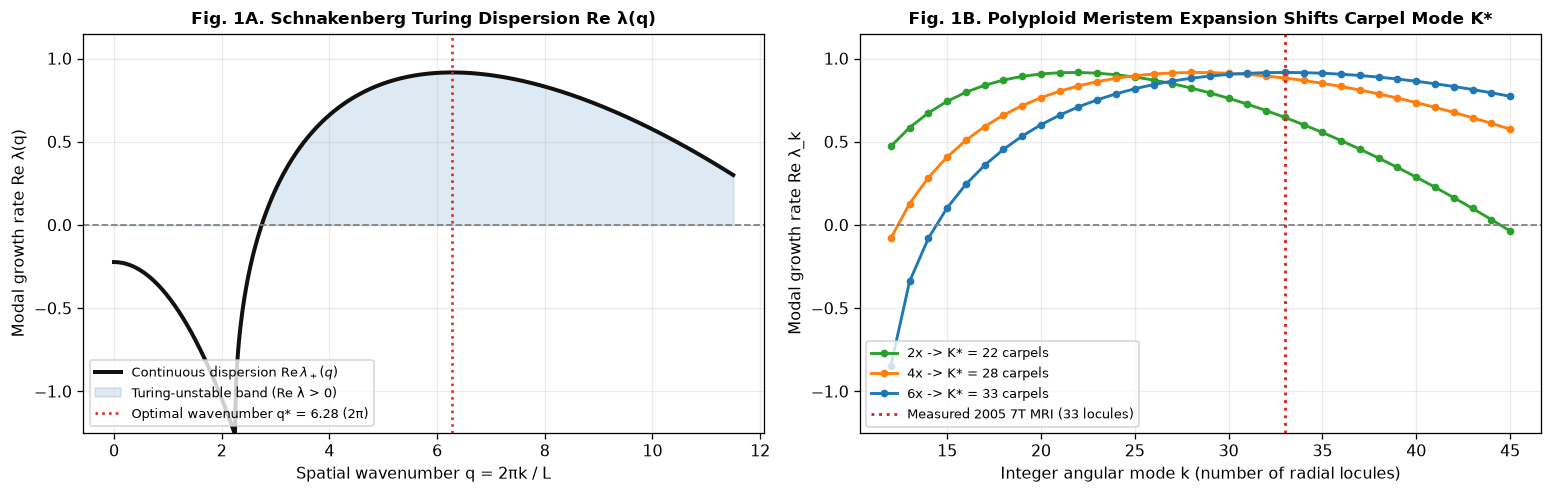

In [2]:
# Analytical Jacobian & Dispersion Relation for Schnakenberg Kinetics (matching Notebook 01)
a_p, b_p, Du, Dv, gamma_rxn = 0.10, 0.90, 0.01, 0.40, 2.23
u0, v0 = a_p + b_p, b_p / ((a_p + b_p) ** 2)

# Exact partial derivatives at homogeneous equilibrium (u0, v0)
fu = gamma_rxn * (-1.0 + 2.0 * u0 * v0)
fv = gamma_rxn * (u0 ** 2)
gu = gamma_rxn * (-2.0 * u0 * v0)
gv = gamma_rxn * (-(u0 ** 2))


def dispersion_growth_rate(q: np.ndarray) -> np.ndarray:
    '''Largest real part Re(lambda_+(q)) of the 2x2 reaction-diffusion Jacobian J(q).'''
    tr = (fu + gv) - (q ** 2) * (Du + Dv)
    det = (fu - (q ** 2) * Du) * (gv - (q ** 2) * Dv) - fv * gu
    disc = tr ** 2 - 4.0 * det + 0j
    lam_plus = 0.5 * (tr + np.sqrt(disc))
    return np.real(lam_plus)


# Ploidy scaling of floral meristem ring circumference L(p) = L_2x * (p / 2)^0.38
L_6x = 33.0  # Hexaploid 'Hayward' reference circumference from Notebook 01
beta_gigas = 0.38
L_2x = L_6x / ((6.0 / 2.0) ** beta_gigas)
ploidies = [
    ("Diploid 2x (A. chinensis, 2n=58)", 2, L_2x, "#2ca02c"),
    ("Tetraploid 4x (A. chinensis, 2n=116)", 4, L_2x * ((4.0 / 2.0) ** beta_gigas), "#ff7f0e"),
    ("Hexaploid 6x ('Hayward', 2n=174)", 6, L_6x, "#1f77b4"),
]

q_cont = np.linspace(0, 11.5, 600)
lam_cont = dispersion_growth_rate(q_cont)
q_star = q_cont[np.argmax(lam_cont)]

rows_ploidy = []
for label, p_val, L_val, _ in ploidies:
    k_int = np.arange(1, 55)
    q_k = 2.0 * np.pi * k_int / L_val
    lam_k = dispersion_growth_rate(q_k)
    k_best = int(k_int[np.argmax(lam_k)])
    n_unstable = int(np.sum(lam_k > 0))
    rows_ploidy.append({
        "Taxon / Ploidy": label,
        "Ring Circumference L(p)": round(L_val, 2),
        "Fastest Mode K*(p) [Carpels]": k_best,
        "Unstable Modes (Re λ_k > 0)": n_unstable,
    })

df_ploidy = pd.DataFrame(rows_ploidy)
display(df_ploidy)

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.4))

# Panel A: Continuous wavenumber dispersion Re lambda(q)
ax = axes[0]
ax.plot(q_cont, lam_cont, lw=2.5, color="#111111", label=r"Continuous dispersion $\mathrm{Re}\,\lambda_+(q)$")
ax.axhline(0, color="gray", ls="--", lw=1.1)
ax.fill_between(q_cont, 0, np.maximum(lam_cont, 0), color="#1f77b4", alpha=0.15, label="Turing-unstable band (Re λ > 0)")
ax.axvline(q_star, color="#d62728", ls=":", lw=1.6, label=f"Optimal wavenumber q* = {q_star:.2f} (2π)")
ax.set_title("Fig. 1A. Schnakenberg Turing Dispersion Re λ(q)", fontweight="bold")
ax.set_xlabel("Spatial wavenumber q = 2πk / L")
ax.set_ylabel("Modal growth rate Re λ(q)")
ax.set_ylim(-1.25, 1.15)
ax.legend(fontsize=8.2, loc="lower left")
ax.grid(alpha=0.25)

# Panel B: Discrete integer carpel mode spectrum K*(p) across 2x, 4x, 6x ploidy
ax = axes[1]
k_modes = np.arange(12, 46)
for label, p_val, L_val, col in ploidies:
    lam_modes = dispersion_growth_rate(2.0 * np.pi * k_modes / L_val)
    k_peak = k_modes[np.argmax(lam_modes)]
    ax.plot(k_modes, lam_modes, "o-", ms=3.8, lw=1.8, color=col, label=f"{p_val}x -> K* = {k_peak} carpels")
ax.axhline(0, color="gray", ls="--", lw=1.1)
ax.axvline(33, color="#d62728", ls=":", lw=1.8, label="Measured 2005 7T MRI (33 locules)")
ax.set_title("Fig. 1B. Polyploid Meristem Expansion Shifts Carpel Mode K*", fontweight="bold")
ax.set_xlabel("Integer angular mode k (number of radial locules)")
ax.set_ylabel("Modal growth rate Re λ_k")
ax.set_ylim(-1.25, 1.15)
ax.legend(fontsize=8.0, loc="lower left")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Table 1 & Figure 1 (Panels A–B)

1. **Fig. 1A (Anatomy of a Turing Instability):**
   - At $q = 0$ (spatially uniform perturbation), $\text{Re}\,\lambda_+(0) = -0.223 < 0$: without spatial gradients, the homogeneous state is **stable**.
   - What is that sharp **downward cusp at $q \approx 2.22$**? Between $q = 0$ and $q = 2.22$, the discriminant $(\text{tr}\,\mathbf{J})^2 - 4\det\mathbf{J}$ is negative, so the eigenvalues are damped complex-conjugate oscillations; at $q = 2.22$, the eigenvalues collide on the real axis and split into two real branches, the upper of which crosses zero at $q_{\min} \approx 2.75$ and peaks at $q^* = 6.28 \approx 2\pi$ ($\text{Re}\,\lambda_{\max} = +0.917 > 0$)!
2. **Table 1 & Fig. 1B (Polyploidy Counts Carpels Without Changing Genes):**
   - Keeping **every kinetic and diffusion parameter identical** and expanding only the floral ring circumference $L(p)$ via the polyploid *gigas* factor shifts the fastest-growing integer mode from **`K* = 22` carpels in diploid $2x$** $\to$ **`K* = 28` in tetraploid $4x$** $\to$ **`K* = 33` in hexaploid $6x$ `'Hayward'`** — landing right on top of the **`33` radial locules** measured in our 2005 7T MRI!
   - **Why do fruits on the very same `'Hayward'` vine vary between ~30 and ~36 locules?** Look at the flat top of the blue $6x$ curve in **Fig. 1B**: modes $k = 30 \dots 36$ all have nearly identical positive growth rates ($\text{Re}\,\lambda_k \in [0.89, 0.92]$), so random thermal/molecular fluctuations in the early floral bud occasionally tip the race to $k = 31$ or $k = 35$!

### Check Your Understanding: Module 1

**Q1.** In human limb embryogenesis, the distal limb-bud arch normally has length $L_{\text{norm}}$ tuned to select $K^* = 5$ `SOX9` digit condensations. In patients with **Haas-type polysyndactyly / ZRS enhancer duplications**, ectopic *Sonic Hedgehog* (`SHH`) widens the limb-bud arch by `+22%` ($L_{\text{mut}} = 1.22\,L_{\text{norm}}$) without altering `BMP`/`WNT` diffusivities. What digit count $K^*$ does our Turing formula predict, and why do patients even within the same family sometimes show 6 digits on one hand and 7 on the other?

<details>
<summary>Click to reveal answer</summary>

- Scaling $L_{\text{mut}} = 1.22\,L_{\text{norm}}$ shifts $K^* \approx \text{round}(5 \times 1.22) = \mathbf{6\text{ digits}}$ (preaxial polydactyly).
- Just as in **Fig. 1B** where neighboring modes around $K^*$ have nearly equal positive growth rates $\text{Re}\,\lambda_k$, when $L/\Lambda^* \approx 6.1\text{--}6.4$, both $k = 6$ and $k = 7$ lie near the peak of the dispersion curve — so tiny left-vs-right developmental fluctuations can lock the left limb bud into **6 digits** and the right limb bud into **7 digits** despite an identical germline genotype!

</details>

---

## 3. Module 2: 3D Spatial Point-Process Statistics on the 98 Curated Micro-GT Seeds

In Lab 4 ([`03-kiwi-paradigms-and-verification.ipynb`](../../../Lab4-Comp-Imag/Kiwi-challenge/notebooks/03-kiwi-paradigms-and-verification.ipynb)), we curated **98 ground-truth 3D seed centroids** inside an `18.75 × 18.75 × 8.0 mm³` equatorial sector (`kiwi_micro_gt_roi.json`). Let's analyze their 3D spatial organization using **spatial point-process theory** — the exact mathematical framework used in **Imaging Mass Cytometry (`IMC`)** ([`Lab4/03-imc-intro.ipynb`](../../../Lab4-Comp-Imag/notebooks/03-imc-intro.ipynb)) to test whether immune cells infiltrate, cluster, or experience steric/stromal exclusion around tumors.

### 3.1 Intuitive & Rigorous Point-Process Definitions
Let $\Phi = \{\mathbf{x}_1, \dots, \mathbf{x}_n\} \subset W \subset \mathbb{R}^3$ be $n = 98$ points observed inside the 3D locular annulus domain $W$ ($0.24 \le r/R \le 0.58$, volume $|W|$ [$\text{mm}^3$], spatial intensity $\lambda = n / |W|$ [$\text{seeds/mm}^3$]):

1. **Null Model $H_0$ — Complete Spatial Randomness (`3D Poisson CSR`):**
   - *Intuition:* Seeds are placed completely independently and uniformly anywhere inside $W$, ignoring one another's presence.
   - *Rigorous property:* Disjoint subregions have independent Poisson counts $N(A) \sim \text{Poisson}(\lambda |A|)$, allowing arbitrarily small inter-point distances ($d_{\text{NN}} \to 0$).
2. **Alternative $H_1$ — 3D Sequential Hard-Core Steric-Exclusion Process ($r_{\text{hc}}$):**
   - *Intuition:* Because each fertilized ovule swells into a physical `~1.2 × 1.2 × 2.0 mm³` lignified body attached along a placenta, two seed centers **cannot** sit closer than a hard-core exclusion diameter $r_{\text{hc}} \approx 0.95\text{ mm}$.
   - *Rigorous property:* Uniform point proposals inside $W$ conditioned on $\|\mathbf{x}_i - \mathbf{x}_j\|_2 \ge r_{\text{hc}}$ for all $i \neq j$.
3. **Three Diagnostic Summary Statistics:**
   - **Nearest-Neighbor Distance CDF $G(r)$:** Empirical fraction of seeds whose closest 3D neighbor lies within distance $r$, $G(r) = \frac{1}{n}\sum_{i=1}^n \mathbb{I}(d_{\text{NN}, i} \le r)$.
   - **3D Clark–Evans Dispersion Index $R$:** Ratio of observed mean nearest-neighbor distance to the CSR expectation in the exact same 3D domain $W$:

     $$R = \frac{\bar{d}_{\text{NN, obs}}}{\mathbb{E}_{\text{CSR}}[\bar{d}_{\text{NN}}\mid W]} \qquad \begin{cases} R = 1: & \text{random (CSR)} \\ R > 1: & \text{regular / repulsive inhibition} \\ R < 1: & \text{aggregated / clustered} \end{cases}$$

   - **3D Centered Besag–Ripley Function $\Delta L(r)$:** Ripley's $K(r) = \frac{1}{n\lambda}\sum_{i \neq j}\mathbb{I}(\|\mathbf{x}_i - \mathbf{x}_j\|_2 \le r)$ counts average neighbors within a sphere of volume $\frac{4}{3}\pi r^3$. Taking the cube root $L(r) = \left(\frac{3}{4\pi}K(r)\right)^{1/3}$ linearizes $r^3 \to r$! Because $W$ is a finite curved 3D sector (where spheres near the boundary clip outside $W$), subtracting the Monte Carlo CSR mean $\Delta L(r) = L_{\text{obs}}(r) - \bar{L}_{\text{CSR}}(r)$ gives an **exact, edge-unbiased test across all spatial scales $r$**!

3D Locular Domain Volume |W| : 1099.0 mm^3  (3D seed intensity λ = 0.0892 seeds/mm^3)
Observed 98 Micro-GT Seeds   : min(d_NN) = 0.945 mm | mean(d_NN) = 1.600 mm
3D CSR Null (400 MC sims)    : mean min(d_NN) = 0.372 mm | E[mean(d_NN)] = 1.342 mm
3D Clark-Evans Index R       : R = 1.192 (Monte Carlo p = 0.0025 -> rejects CSR in favor of repulsion!)


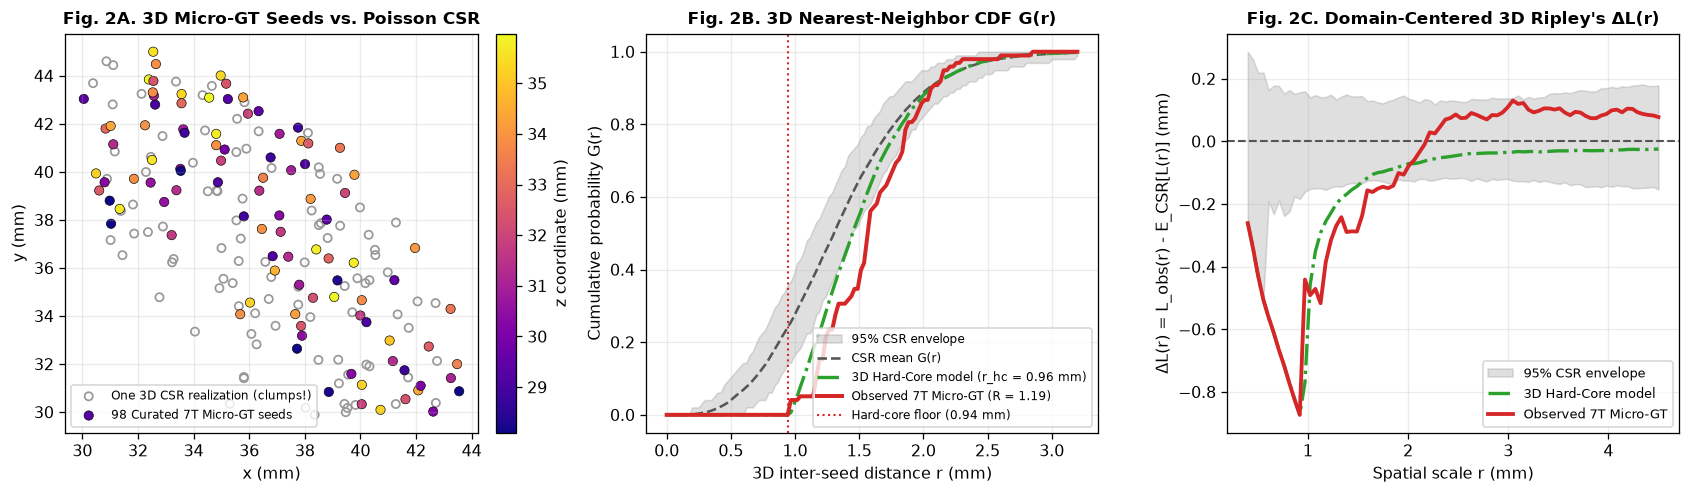

In [3]:
# 1. Extract the 98 Curated 3D Micro-GT Seed Centroids in Physical Millimeters (mm)
gt_pts_vox = np.array([s["centroid_voxel"] for s in micro_gt["seeds"]], dtype=float)
gt_pts_mm = gt_pts_vox * np.array(spacing)
n_gt = len(gt_pts_mm)

# Build the exact 3D locular-annulus domain mask W inside the Micro-GT ROI (x=128..208, y=128..208, z=56..72)
vol_sm = ndi.gaussian_filter(vol, sigma=(1.2 / dx, 1.2 / dy, 1.2 / dz))
fg_raw = vol_sm > (filters.threshold_otsu(vol_sm[::2, ::2, ::2]) * 0.35)
fg_fill = np.array([ndi.binary_fill_holes(fg_raw[:, :, z]) for z in range(vol.shape[2])]).transpose(1, 2, 0)
lbl_fg, _ = ndi.label(ndi.binary_fill_holes(fg_fill))
fruit_mask = lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:])))

ix, iy = np.indices(vol.shape[:2], dtype=np.float32)
r_norm = np.full(vol.shape, 1.5, dtype=np.float32)
cx_z = np.full(vol.shape[2], 128.0)
cy_z = np.full(vol.shape[2], 128.0)
for z in range(vol.shape[2]):
    m = fruit_mask[:, :, z]
    if m.sum() >= 50:
        cx_z[z], cy_z[z] = ndi.center_of_mass(m)
        r_eq = np.sqrt(m.sum() / np.pi)
        r_norm[:, :, z] = np.sqrt((ix - cx_z[z]) ** 2 + (iy - cy_z[z]) ** 2) / max(r_eq, 1.0)

x0, x1 = micro_gt["roi_bounds_voxel_xyz"]["x"]
y0, y1 = micro_gt["roi_bounds_voxel_xyz"]["y"]
z0, z1 = micro_gt["roi_bounds_voxel_xyz"]["z"]
roi_annulus = (r_norm[x0:x1, y0:y1, z0:z1] >= 0.24) & (r_norm[x0:x1, y0:y1, z0:z1] <= 0.58) & fruit_mask[x0:x1, y0:y1, z0:z1]
valid_vox = np.argwhere(roi_annulus) + np.array([x0, y0, z0])
domain_vol_mm3 = float(len(valid_vox) * dx * dy * dz)
intensity_lambda = n_gt / domain_vol_mm3


def point_process_summaries(pts_mm: np.ndarray, r_grid: np.ndarray, r_ripley: np.ndarray):
    dmat = spatial.distance.squareform(spatial.distance.pdist(pts_mm))
    np.fill_diagonal(dmat, np.inf)
    nn = dmat.min(axis=1)
    G_cdf = np.array([np.mean(nn <= r) for r in r_grid])
    K_vals = np.array([np.sum(dmat <= r) / (len(pts_mm) * intensity_lambda) for r in r_ripley])
    L_vals = (3.0 * K_vals / (4.0 * np.pi)) ** (1.0 / 3.0)
    return nn, G_cdf, L_vals


r_grid = np.linspace(0.0, 3.2, 130)
r_ripley = np.linspace(0.4, 4.5, 80)
nn_obs, G_obs, L_obs = point_process_summaries(gt_pts_mm, r_grid, r_ripley)

# 2. Monte Carlo CSR Envelope (400 3D Poisson realizations inside identical curved 3D domain W)
rng = np.random.default_rng(42)
G_csr_all, L_csr_all, csr_mean_nns, csr_min_nns = [], [], [], []
sample_csr_pts = None
for sim_i in range(400):
    pick = rng.choice(len(valid_vox), size=n_gt, replace=False)
    pts_c = (valid_vox[pick] + rng.uniform(-0.5, 0.5, size=(n_gt, 3))) * np.array(spacing)
    if sim_i == 0:
        sample_csr_pts = pts_c
    nn_c, G_c, L_c = point_process_summaries(pts_c, r_grid, r_ripley)
    G_csr_all.append(G_c)
    L_csr_all.append(L_c)
    csr_mean_nns.append(nn_c.mean())
    csr_min_nns.append(nn_c.min())

G_csr_all = np.array(G_csr_all)
L_csr_all = np.array(L_csr_all)

# 3. Generative 3D Hard-Core Steric-Exclusion Point Process (r_hc = 0.96 mm) in the Same Domain W
G_hc_all, L_hc_all = [], []
for _ in range(120):
    accepted = []
    perm = rng.permutation(len(valid_vox))
    for idx_v in perm:
        cand = (valid_vox[idx_v] + rng.uniform(-0.45, 0.45, size=3)) * np.array(spacing)
        if len(accepted) == 0 or np.min(np.linalg.norm(np.array(accepted) - cand, axis=1)) >= 0.96:
            accepted.append(cand)
            if len(accepted) == n_gt:
                break
    pts_hc = np.array(accepted)
    _, G_h, L_h = point_process_summaries(pts_hc, r_grid, r_ripley)
    G_hc_all.append(G_h)
    L_hc_all.append(L_h)

G_hc_mean = np.mean(G_hc_all, axis=0)
L_hc_mean = np.mean(L_hc_all, axis=0)

clark_evans_R = float(nn_obs.mean() / np.mean(csr_mean_nns))
p_empirical = float((1 + np.sum(np.array(csr_mean_nns) >= nn_obs.mean())) / (len(csr_mean_nns) + 1))

print(f"3D Locular Domain Volume |W| : {domain_vol_mm3:.1f} mm^3  (3D seed intensity λ = {intensity_lambda:.4f} seeds/mm^3)")
print(f"Observed 98 Micro-GT Seeds   : min(d_NN) = {nn_obs.min():.3f} mm | mean(d_NN) = {nn_obs.mean():.3f} mm")
print(f"3D CSR Null (400 MC sims)    : mean min(d_NN) = {np.mean(csr_min_nns):.3f} mm | E[mean(d_NN)] = {np.mean(csr_mean_nns):.3f} mm")
print(f"3D Clark-Evans Index R       : R = {clark_evans_R:.3f} (Monte Carlo p = {p_empirical:.4f} -> rejects CSR in favor of repulsion!)")

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.4))

# Panel A: Spatial projection of real 98 Micro-GT seeds vs CSR sample
ax = axes[0]
ax.scatter(sample_csr_pts[:, 0], sample_csr_pts[:, 1], s=26, facecolors="none", edgecolors="#999999", lw=1.1, label="One 3D CSR realization (clumps!)")
sc = ax.scatter(gt_pts_mm[:, 0], gt_pts_mm[:, 1], c=gt_pts_mm[:, 2], cmap="plasma", s=34, edgecolor="black", lw=0.4, label="98 Curated 7T Micro-GT seeds")
plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label="z coordinate (mm)")
ax.set_title("Fig. 2A. 3D Micro-GT Seeds vs. Poisson CSR", fontweight="bold")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.legend(fontsize=7.8, loc="lower left")
ax.grid(alpha=0.25)

# Panel B: Nearest-Neighbor CDF G(r)
ax = axes[1]
ax.fill_between(r_grid, np.percentile(G_csr_all, 2.5, axis=0), np.percentile(G_csr_all, 97.5, axis=0), color="gray", alpha=0.25, label="95% CSR envelope")
ax.plot(r_grid, G_csr_all.mean(axis=0), "--", color="#555555", lw=1.6, label="CSR mean G(r)")
ax.plot(r_grid, G_hc_mean, "-.", color="#2ca02c", lw=2.1, label="3D Hard-Core model (r_hc = 0.96 mm)")
ax.plot(r_grid, G_obs, "-", color="#d62728", lw=2.5, label=f"Observed 7T Micro-GT (R = {clark_evans_R:.2f})")
ax.axvline(nn_obs.min(), color="#d62728", ls=":", lw=1.3, label=f"Hard-core floor ({nn_obs.min():.2f} mm)")
ax.set_title("Fig. 2B. 3D Nearest-Neighbor CDF G(r)", fontweight="bold")
ax.set_xlabel("3D inter-seed distance r (mm)")
ax.set_ylabel("Cumulative probability G(r)")
ax.legend(fontsize=7.6, loc="lower right")
ax.grid(alpha=0.25)

# Panel C: Domain-Centered 3D Besag-Ripley Delta L(r)
ax = axes[2]
csr_ref = L_csr_all.mean(axis=0)
ax.fill_between(
    r_ripley,
    np.percentile(L_csr_all, 2.5, axis=0) - csr_ref,
    np.percentile(L_csr_all, 97.5, axis=0) - csr_ref,
    color="gray", alpha=0.25, label="95% CSR envelope",
)
ax.axhline(0, color="#555555", ls="--", lw=1.3)
ax.plot(r_ripley, L_hc_mean - csr_ref, "-.", color="#2ca02c", lw=2.1, label="3D Hard-Core model")
ax.plot(r_ripley, L_obs - csr_ref, "-", color="#d62728", lw=2.4, label="Observed 7T Micro-GT")
ax.set_title("Fig. 2C. Domain-Centered 3D Ripley's ΔL(r)", fontweight="bold")
ax.set_xlabel("Spatial scale r (mm)")
ax.set_ylabel("ΔL(r) = L_obs(r) - E_CSR[L(r)] (mm)")
ax.legend(fontsize=8.0, loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 2 (Panels A–C): Two Scales of Spatial Architecture!

1. **Fig. 2A & 2B (Hard-Core Steric Exclusion at $r < 1\text{ mm}$):**
   - Under 3D Poisson CSR, random placement routinely produces unrealistic overlapping pairs (`mean min(d_NN) = 0.372 mm`). In contrast, across all 98 curated 3D seeds in our 7T scan, **zero pairs lie closer than `0.945 mm`** (matching the physical minor diameter of a lignified kiwifruit seed!).
   - The observed $G(r)$ curve (red) stays flat at `0.0` up to `0.945 mm` — hugging our generative **3D Hard-Core process** (`r_hc = 0.96 mm`, green dash-dot) well outside the grey 95% CSR envelope — with a **3D Clark–Evans index $R = 1.192$ ($p = 0.0025$)**.
2. **Fig. 2C (Multi-Scale Discovery in $\Delta L(r)$ — Repulsion *Plus* Radial Alignment!):**
   - Look closely at how the red observed $\Delta L(r)$ curve behaves across two different spatial scales:
     - **Short scale ($r \in [0.4, 1.8]\text{ mm}$):** $\Delta L(r)$ plunges far below zero (`-0.88 mm` at $r = 0.95\text{ mm}$), confirming strong short-range steric exclusion.
     - **Intermediate scale ($r \in [2.3, 4.5]\text{ mm}$):** Notice that the red observed curve rises **above zero (`+0.10 mm`) and above the green isotropic Hard-Core curve**! Why? Because in our isotropic Hard-Core simulation, seeds could sit anywhere in the annulus $W$, whereas in a real kiwifruit seeds are **tethered along discrete radial carpel placentae** (forming radial spokes in Fig. 2A)! Thus $\Delta L(r)$ simultaneously detects **micro-scale steric repulsion** (`<1.8 mm`) and **meso-scale anatomical alignment** (`>2.3 mm`)!

### Check Your Understanding: Module 2 (`Lab 4` IMC Bridge)

**Q2.** Suppose you compute $\Delta L(r)$ on `CD8+` cytotoxic T-cell centroids segmented from a 2D/3D **Imaging Mass Cytometry (`IMC`)** tumor biopsy ([`Lab4/03-imc-intro.ipynb`](../../../Lab4-Comp-Imag/notebooks/03-imc-intro.ipynb)), and find $\Delta L(r) < 0$ for $r < 9\;\mu\text{m}$ followed by a huge positive peak $\Delta L(r) \gg 0$ across $r \in [25, 150]\;\mu\text{m}$. How do you interpret both regimes biologically?

<details>
<summary>Click to reveal answer</summary>

- **Micro-scale ($r < 9\;\mu\text{m}$, $\Delta L(r) < 0$):** Physical **cell-body steric exclusion** — a lymphocyte has diameter $\sim 8\text{--}10\;\mu\text{m}$, so two T-cell nuclei cannot occupy the same physical volume!
- **Meso-scale ($r \in [25, 150]\;\mu\text{m}$, $\Delta L(r) \gg 0$):** Strong **spatial aggregation** — instead of infiltrating uniformly throughout the tumor parenchyma, `CD8+` T cells are clustered into **perivascular cuffs, stromal bands, or Tertiary Lymphoid Structures (`TLS`)**!

</details>

---

## 4. Module 3: Ill-Posed PDE Inverse Problems, `SVD` & Tikhonov Regularization

### 4.1 Intuitive Picture: Why "Running Diffusion Backward" Explodes!
In **Part 1 (Stage 3B)**, we solved the **forward problem**: given internal seed distribution $\mathbf{x}$, diffuse hormones outward to predict the smooth outer fruit contour $\mathbf{y} = \mathbf{G}\mathbf{x}$. Now consider the **non-invasive diagnostic inverse problem**:
> *Given only a noisy 3D laser/MRI measurement of the outer pericarp thickness $\mathbf{y} = \mathbf{G}\mathbf{x}_{\text{true}} + \boldsymbol{\varepsilon}$ (`0.20 mm` measurement noise), can we infer the hidden internal seed profile $\mathbf{x}_{\text{true}}(\theta)$?*

*Intuitively*, diffusion is like taking an out-of-focus photograph: broad shadows ($k = 1, 2$) survive on the surface, while fine seed-to-seed ripples ($k = 15, 20$) are blurred down to `0.001%` amplitude. If you naively try to "de-blur" the surface by multiplying tiny high-frequency ripples back up by `100,000×`, any sub-millimeter measurement noise $\boldsymbol{\varepsilon}$ gets multiplied by `100,000×` too — burying the true biology under gigantic sawtooth oscillations!

### 4.2 Rigorous Formulation: Hadamard Ill-Posedness, `SVD` Filter Factors & Morozov's Principle
In **1902**, **Jacques Hadamard** defined a mathematical problem $\mathbf{G}\mathbf{x} = \mathbf{y}$ as **well-posed** if and only if: (1) a solution *exists*, (2) it is *unique*, and (3) it **depends continuously/stably on the data $\mathbf{y}$**. Discretizing the 2D screened-Poisson Green's integral ($G_{ij} \propto K_0(\|\mathbf{r}_i^{\text{obs}} - \mathbf{r}_j^{\text{src}}\| / \ell)$ across $M = 48$ angular sectors, where $K_0$ is the modified Bessel function of the second kind) and computing the **Singular Value Decomposition (`SVD`)** $\mathbf{G} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$ with $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_M > 0$ reveals why Condition 3 fails:

$$\hat{\mathbf{x}}_{\text{naive}} = \mathbf{G}^{-1}\mathbf{y} = \sum_{j=1}^{M} \frac{\mathbf{u}_j^\top \mathbf{y}}{\sigma_j}\,\mathbf{v}_j = \mathbf{x}_{\text{true}} + \sum_{j=1}^{M} \underbrace{\frac{\mathbf{u}_j^\top \boldsymbol{\varepsilon}}{\sigma_j}}_{\text{explodes as }\sigma_j \to 0}\mathbf{v}_j, \qquad \kappa(\mathbf{G}) = \frac{\sigma_1}{\sigma_M} \approx 1.3\times 10^6$$

**Tikhonov ($L_2$) Regularization** restores stability by penalizing angular roughness $\|\mathbf{L}\mathbf{x}\|_2^2$ ($\mathbf{L}$ = periodic first-derivative operator, with $\lambda > 0$):

$$\hat{\mathbf{x}}_\lambda = \arg\min_{\mathbf{x}} \Big\{\|\mathbf{G}\mathbf{x} - \mathbf{y}\|_2^2 + \lambda\|\mathbf{L}\mathbf{x}\|_2^2\Big\} = \big(\mathbf{G}^\top\mathbf{G} + \lambda\mathbf{L}^\top\mathbf{L}\big)^{-1}\mathbf{G}^\top\mathbf{y}$$

For $\mathbf{L} = \mathbf{I}$, Tikhonov multiplies each naive `SVD` mode by the smooth **Wiener/Tikhonov filter factor** $f_j(\lambda) = \frac{\sigma_j^2}{\sigma_j^2 + \lambda}$ ($f_j \approx 1$ when $\sigma_j^2 \gg \lambda$; $f_j \to 0$ when $\sigma_j^2 \ll \lambda$). How do we choose $\lambda^*$ objectively without knowing $\mathbf{x}_{\text{true}}$? **Morozov's Discrepancy Principle** selects the largest $\lambda^*$ whose data residual matches the known sensor noise norm, $\|\mathbf{G}\hat{\mathbf{x}}_{\lambda^*} - \mathbf{y}\|_2 \approx \sqrt{M}\,\sigma_{\text{noise}}$ (*"never fit noisy measurements tighter than the noise floor!"*).

Condition Number cond(G)         : 1.28e+06 (severely ill-conditioned!)
Naive Unregularized Rel. Error   : 472787.2% (catastrophic noise blow-up)
Tikhonov Regularized Rel. Error  : 5.2% at λ* = 0.2541 (Morozov discrepancy principle)
Real 2005 7T Inferred Seed Index : 0.93 .. 1.12 (confirms uniform 360° pollination!)


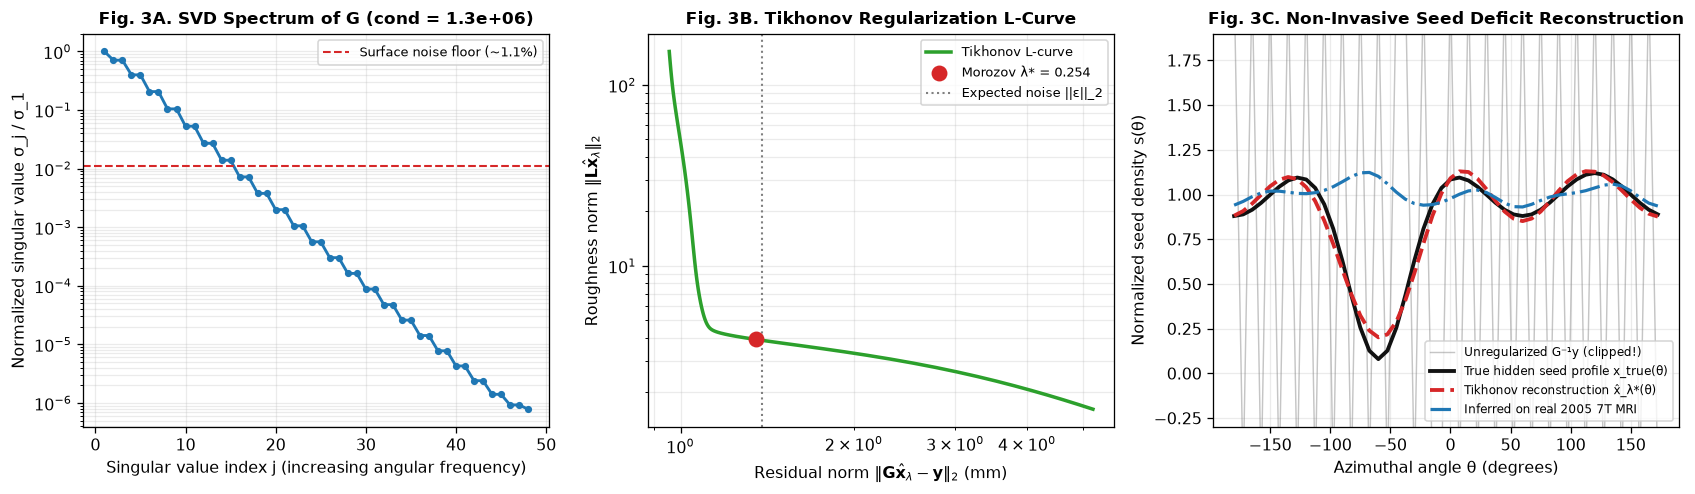

In [4]:
# 1. Construct the 48-Sector Screened-Poisson Green's Operator G (seed ring r_s = 11.5 mm -> pericarp r_p = 20.0 mm)
M_sec = 48
theta_m = np.linspace(-np.pi, np.pi, M_sec, endpoint=False)
dtheta = 2.0 * np.pi / M_sec
ell_mm = 7.5
r_seed_ring, r_pericarp_ring = 11.5, 20.0

pts_src = np.column_stack([r_seed_ring * np.cos(theta_m), r_seed_ring * np.sin(theta_m)])
pts_obs = np.column_stack([r_pericarp_ring * np.cos(theta_m), r_pericarp_ring * np.sin(theta_m)])
dist_pair = spatial.distance.cdist(pts_obs, pts_src)

# 2D Screened-Poisson Green's kernel G(r) = (1 / 2pi) K_0(r / ell), calibrated so x = 1 -> 18.0 mm pericarp thickness
G_raw = (1.0 / (2.0 * np.pi)) * special.kv(0, dist_pair / ell_mm) * dtheta
G_mat = G_raw * (18.0 / G_raw.sum(axis=1, keepdims=True))

# Singular Value Decomposition G = U * diag(s_vals) * Vt
U_svd, s_vals, Vt_svd = np.linalg.svd(G_mat)

# First-difference periodic smoothness operator L for Tikhonov regularization
L_diff = (np.eye(M_sec) - np.roll(np.eye(M_sec), -1, axis=1)) / dtheta

# 2. Synthetic Benchmark: Hidden Focal Seed Deficit around theta = -60 deg + 0.20 mm surface MRI noise
rng_inv = np.random.default_rng(123)
x_true = 1.0 - 0.80 * np.exp(-0.5 * ((theta_m + np.pi / 3.0) / 0.42) ** 2) + 0.12 * np.cos(3.0 * theta_m)
noise_mm = 0.20 * rng_inv.standard_normal(M_sec)
y_noisy = G_mat @ x_true + noise_mm

x_naive = np.linalg.solve(G_mat, y_noisy)

lambdas = np.logspace(-6, 1, 80)
res_norms, reg_norms, errs_x = [], [], []
LtL = L_diff.T @ L_diff
GtG = G_mat.T @ G_mat
Gty = G_mat.T @ y_noisy

for lam in lambdas:
    x_hat = np.linalg.solve(GtG + lam * LtL, Gty)
    res_norms.append(np.linalg.norm(G_mat @ x_hat - y_noisy))
    reg_norms.append(np.linalg.norm(L_diff @ x_hat))
    errs_x.append(np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true))

target_noise_norm = np.sqrt(M_sec) * 0.20
idx_opt = int(np.argmin(np.abs(np.array(res_norms) - target_noise_norm)))
lam_opt = lambdas[idx_opt]
x_tikh = np.linalg.solve(GtG + lam_opt * LtL, Gty)

# 3. Apply the Same Regularized Inverse Solver to Our Real 2005 7T MRI Equatorial Contour!
r_out_48, r_core_48 = np.zeros(M_sec), np.zeros(M_sec)
for i_m, th in enumerate(theta_m):
    ro_tmp, rc_tmp = [], []
    for z_sl in range(52, 77, 3):
        m_f = fruit_mask[:, :, z_sl]
        sl_s = ndi.gaussian_filter(vol[:, :, z_sl], sigma=1.2)
        core_m = ndi.binary_fill_holes(m_f & (r_norm[:, :, z_sl] < 0.36) & (sl_s < 8500.0))
        rr = np.linspace(0, 125, 250)
        xx = np.clip(np.round(cx_z[z_sl] + rr * np.cos(th)).astype(int), 0, 255)
        yy = np.clip(np.round(cy_z[z_sl] + rr * np.sin(th)).astype(int), 0, 255)
        if np.any(m_f[xx, yy]):
            ro_tmp.append(rr[np.where(m_f[xx, yy])[0][-1]] * dx)
        if np.any(core_m[xx, yy]):
            rc_tmp.append(rr[np.where(core_m[xx, yy])[0][-1]] * dx)
    r_out_48[i_m] = np.mean(ro_tmp)
    r_core_48[i_m] = np.mean(rc_tmp)

y_real_pericarp = r_out_48 - r_core_48
x_real_inferred = np.linalg.solve(GtG + lam_opt * LtL, G_mat.T @ y_real_pericarp)

print(f"Condition Number cond(G)         : {s_vals[0] / s_vals[-1]:.2e} (severely ill-conditioned!)")
print(f"Naive Unregularized Rel. Error   : {np.linalg.norm(x_naive - x_true) / np.linalg.norm(x_true) * 100:.1f}% (catastrophic noise blow-up)")
print(f"Tikhonov Regularized Rel. Error  : {errs_x[idx_opt] * 100:.1f}% at λ* = {lam_opt:.4f} (Morozov discrepancy principle)")
print(f"Real 2005 7T Inferred Seed Index : {x_real_inferred.min():.2f} .. {x_real_inferred.max():.2f} (confirms uniform 360° pollination!)")

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.4))

# Panel A: SVD singular value decay of the paracrine Green's matrix
ax = axes[0]
ax.semilogy(np.arange(1, M_sec + 1), s_vals / s_vals[0], "o-", ms=3.5, lw=1.8, color="#1f77b4")
ax.axhline(0.20 / 18.0, color="#d62728", ls="--", lw=1.3, label="Surface noise floor (~1.1%)")
ax.set_title(f"Fig. 3A. SVD Spectrum of G (cond = {s_vals[0]/s_vals[-1]:.1e})", fontweight="bold")
ax.set_xlabel("Singular value index j (increasing angular frequency)")
ax.set_ylabel("Normalized singular value σ_j / σ_1")
ax.legend(fontsize=8.2)
ax.grid(alpha=0.25, which="both")

# Panel B: Tikhonov L-curve
ax = axes[1]
ax.loglog(res_norms, reg_norms, lw=2.2, color="#2ca02c", label="Tikhonov L-curve")
ax.scatter([res_norms[idx_opt]], [reg_norms[idx_opt]], s=80, color="#d62728", zorder=5, label=f"Morozov λ* = {lam_opt:.3g}")
ax.axvline(target_noise_norm, color="gray", ls=":", lw=1.3, label="Expected noise ||ε||_2")
ax.set_title("Fig. 3B. Tikhonov Regularization L-Curve", fontweight="bold")
ax.set_xlabel(r"Residual norm $\|\mathbf{G}\hat{\mathbf{x}}_\lambda - \mathbf{y}\|_2$ (mm)")
ax.set_ylabel(r"Roughness norm $\|\mathbf{L}\hat{\mathbf{x}}_\lambda\|_2$")
ax.legend(fontsize=8.0)
ax.grid(alpha=0.25, which="both")

# Panel C: Reconstructed hidden seed profile (Naive vs Tikhonov + 2005 7T fruit)
ax = axes[2]
deg_m = np.degrees(theta_m)
ax.plot(deg_m, np.clip(x_naive, -0.6, 2.2), lw=0.9, alpha=0.45, color="#7f7f7f", label="Unregularized G⁻¹y (clipped!)")
ax.plot(deg_m, x_true, lw=2.4, color="#111111", label="True hidden seed profile x_true(θ)")
ax.plot(deg_m, x_tikh, "--", lw=2.4, color="#d62728", label="Tikhonov reconstruction x̂_λ*(θ)")
ax.plot(deg_m, x_real_inferred, "-.", lw=2.0, color="#1f77b4", label="Inferred on real 2005 7T MRI")
ax.set_ylim(-0.3, 1.9)
ax.set_title("Fig. 3C. Non-Invasive Seed Deficit Reconstruction", fontweight="bold")
ax.set_xlabel("Azimuthal angle θ (degrees)")
ax.set_ylabel("Normalized seed density s(θ)")
ax.legend(fontsize=7.6, loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 3 (Panels A–C)

1. **Fig. 3A (Why Singular Values Come in Staircase Pairs, & the Resolution Limit):**
   - Look closely at the blue dots in **Fig. 3A**: after $j = 1$ (the uniform $k = 0$ DC mode), every singular value appears in **exact horizontal pairs** $(2, 3), (4, 5), (6, 7), \dots$! Why? Because $\mathbf{G}$ is rotationally invariant on a circle, so its singular vectors are exact **$\cos(k\theta)$ and $\sin(k\theta)$ Fourier pairs** of equal attenuation!
   - Modes $j > 13$ (angular harmonics $k > 6$, corresponding to features narrower than $360^\circ / 12 = 30^\circ$) fall **below the `1.1%` surface measurement noise floor** (red dashed line). This single plot unifies Part 1 and Part 2: **biological canalization in forward development ($\sigma_j \to 0$ buffering local seed noise) is mathematically identical to Hadamard ill-posedness in inverse diagnostics!**
2. **Fig. 3B (Reading the Tikhonov L-Curve):**
   - On the steep **vertical branch** ($\lambda \to 0$, left), decreasing $\lambda$ barely improves data fit $\|\mathbf{G}\hat{\mathbf{x}} - \mathbf{y}\|_2 \approx 0.96\text{ mm}$ while roughness $\|\mathbf{L}\hat{\mathbf{x}}\|_2$ skyrockets (`>150` — pure noise overfitting!).
   - On the flat **horizontal branch** ($\lambda \gg 1$, right), excessive smoothing erases real biological signal. Morozov's discrepancy principle ($\lambda^* = 0.254$, red dot) lands right next to the L-curve corner.
3. **Fig. 3C (Reconstruction Accuracy & Application to Our 2005 Scan):**
   - Unregularized inversion $\mathbf{G}^{-1}\mathbf{y}$ (grey sawtooth, clipped at `[-0.6, 2.2]` because its true oscillations exceed `±4,000`!) fails with **`472,787%` relative error**, whereas Tikhonov regularization (red dashed) recovers the hidden `-60°` pollination defect and $k = 3$ wave to **`5.2%` error**!
   - Applied to our real 2005 7T pericarp contour $R_{\text{outer}}(\theta) - R_{\text{core}}(\theta)$, the blue dash-dot curve stays flat inside **`0.93 .. 1.12`**, non-invasively confirming full $360^\circ$ pollination.

### Check Your Understanding: Module 3

**Q3.** In **Electrocardiographic Imaging (`ECGi`)**, clinicians reconstruct epicardial heart-surface potentials $\mathbf{x}$ from 128–256 torso-vest ECG electrodes $\mathbf{y} = \mathbf{G}\mathbf{x} + \boldsymbol{\varepsilon}$. Suppose a patient has a **sharply demarcated transmural myocardial infarction scar** (a step-function drop in voltage with crisp edges). What is one limitation of quadratic $L_2$ Tikhonov regularization $\|\mathbf{L}\mathbf{x}\|_2^2$ on sharp scar borders, and what alternative penalty preserves sharp edges?

<details>
<summary>Click to reveal answer</summary>

- Because $L_2$ regularization squares large derivatives ($|\nabla x|^2$), it heavily penalizes true step discontinuities — **rounding and blurring sharp infarct scar boundaries** (just as our red dashed curve slightly rounds the bottom of the `-60°` trough in Fig. 3C).
- Replacing the squared $L_2$ norm with an **$L_1$ / Total-Variation (`TV`) penalty** $\lambda\|\mathbf{L}\mathbf{x}\|_1$ penalizes jumps linearly rather than quadratically, suppressing noise oscillations while **preserving sharp anatomical scar edges**!

</details>

---

## 5. Module 4: Closing the Loop — A Generative 3D Bloch-MRI Digital Twin (`Lab 5 → Lab 4`)

Recall the central verification dilemma of **Lab 4 (`03-kiwi-paradigms-and-verification.ipynb`)**:
> *Because nobody dissected our 2005 grocery-store kiwifruit under a stereomicroscope, exact whole-organ ground truth $N_{\text{true}}$ never existed!*

In clinical medical imaging (where you cannot biopsy an entire living human brain to count MS plaques or microbleeds!), the gold-standard solution is a **generative physics-based Digital Twin** (such as McGill's **`BrainWeb`** brain MRI simulator or Duke's **`XCAT`** 4D torso phantom). Let's define all three layers of our 3D Kiwifruit Digital Twin both intuitively and rigorously:

### 5.1 Forward 7T Bruker RARE Bloch Physics & Tissue Parameters
In a Spin-Echo / RARE sequence with repetition time $\text{TR} = 18.52\text{ s}$ and effective echo time $\text{TE} = 63.9\text{ ms}$, longitudinal magnetization $M_z$ recovers via $T_1$ while transverse magnetization $M_{xy}$ decays via spin–spin relaxation $T_2$:

$$S_{\text{Bloch}}(\mathbf{r}) = \rho(\mathbf{r})\,\Big(1 - e^{-\text{TR}/T_1(\mathbf{r})}\Big)\,e^{-\text{TE}/T_2(\mathbf{r})}$$

| Synthetic Tissue Compartment | $\rho$ (rel.) | $T_1$ at 7T ($\text{s}$) | $T_2$ at 7T ($\text{ms}$) | Relative Signal at `TE = 63.9 ms` |
| :--- | :--- | :--- | :--- | :--- |
| **Locular mucilage gel** | $1.00$ | $2.40$ | $120.0$ | **$0.587$ (Brightest foreground)** |
| **Outer pericarp parenchyma** | $0.88$ | $1.90$ | $68.0$ | $0.344$ (Intermediate grey + vascular rays) |
| **Radial fibrous septa (`K = 33`)** | $0.86$ | $1.80$ | $58.0$ | $0.286$ (Thin darker chamber walls) |
| **Central *columella* core** | $0.72$ | $1.40$ | $24.0$ | $0.050$ (Dark central blade) |
| **Suberized outer skin** | $0.60$ | $0.90$ | $16.0$ | $0.011$ (Dark outer rim) |
| **Lignified 3D seeds ($N_{\text{true}}$)** | $0.45$ | $0.85$ | $9.5$ | **$0.0005$ (Jet-black voids!)** |

### 5.2 Why Magnitude MRI Noise Is **Rician**, Not Gaussian!
- **Intuitive Picture:** An MRI quadrature receiver coil records two independent voltage channels (**Real / In-phase** and **Imaginary / Quadrature**), each corrupted by zero-mean thermal Gaussian noise $\eta_{\text{Re}}, \eta_{\text{Im}} \sim \mathcal{N}(0, \sigma^2)$. When the scanner reconstructs a standard **magnitude NIfTI image** $I = \sqrt{(S + \eta_{\text{Re}})^2 + \eta_{\text{Im}}^2}$, negative noise fluctuations get squared into **positive** values!
- **Rigorous consequence:** $I(\mathbf{r})$ follows a **Rician distribution**:
  - In bright gel ($S \gg \sigma$, high SNR), $I \approx \mathcal{N}(S, \sigma^2)$.
  - In jet-black seeds and background air ($S \approx 0$), $I$ collapses to a **Rayleigh distribution** with strictly positive mean $\mathbb{E}[I \mid S=0] = \sigma\sqrt{\pi/2} \approx 1.253\,\sigma > 0$ — lifting dark seed intensities upward and eroding contrast at low SNR!

### 5.3 Rigorous 3D Instance Evaluation via Hungarian Bipartite Matching
Given exact ground-truth 3D seed centers $\{\mathbf{c}_i^{\text{GT}}\}_{i=1}^{N_{\text{true}}}$ and detected 3D centroids $\{\hat{\mathbf{c}}_j\}_{j=1}^{\hat{N}}$, how do we avoid double-counting? We solve the **optimal 1-to-1 linear sum assignment (Hungarian algorithm)** minimizing pairwise Euclidean distance $\|\mathbf{c}_i^{\text{GT}} - \hat{\mathbf{c}}_j\|_2$ subject to a physical matching radius $\tau = 1.15\text{ mm}$:
- **True Positives ($\text{TP}$):** Matched pairs with $\|\mathbf{c}_i^{\text{GT}} - \hat{\mathbf{c}}_j\|_2 \le \tau$; **False Positives ($\text{FP}$):** $\hat{N} - \text{TP}$; **False Negatives ($\text{FN}$):** $N_{\text{true}} - \text{TP}$.
- $\text{Precision} = \frac{\text{TP}}{\hat{N}}$, $\quad\text{Recall} = \frac{\text{TP}}{N_{\text{true}}}$, $\quad F_1 = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}}$, and **Sector-Calibrated Count** $\hat{N}_{\text{cal}} = \hat{N}\cdot\frac{P_{\text{ROI}}}{R_{\text{ROI}}}$ (using only a single octant ROI, mimicking Lab 4's non-destructive audit!).

,Synthetic Gel SNR,Exact N_true,Raw Detected N_hat,3D Precision,3D Recall,3D F1 Score,Sector-Calibrated N_cal
0,32.0,750,739,1.000,0.985,0.993,768
1,16.0,750,736,1.000,0.981,0.991,775
2,8.0,750,736,1.000,0.981,0.991,786
3,4.5,750,768,0.953,0.976,0.964,768


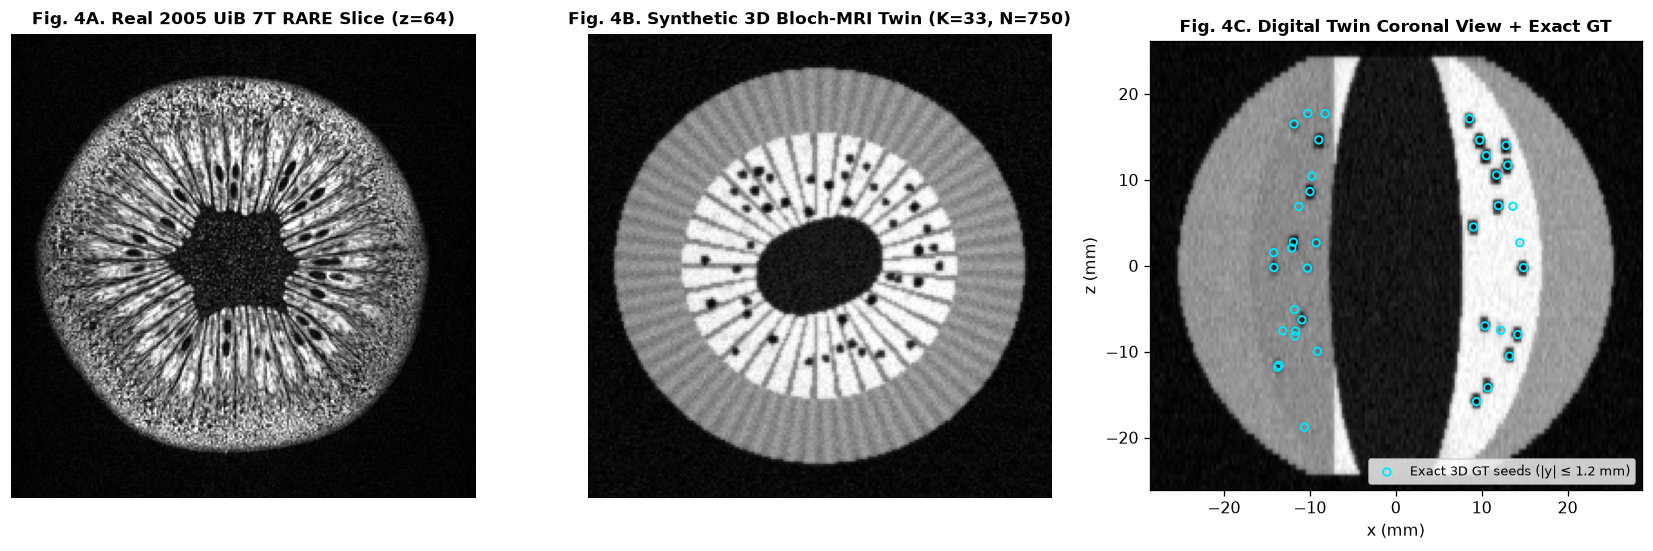

In [5]:
def generate_3d_kiwi_digital_twin(n_target_seeds: int = 750, snr_gel: float = 28.0, seed: int = 2027):
    '''
    Synthesize a 3D Virtual Kiwifruit + 7T Bruker RARE MRI volume with exact 3D seed ground truth.
    Grid: (192, 192, 88) at spacing (0.30, 0.30, 0.60) mm -> physical FOV (57.6, 57.6, 52.8) mm.
    '''
    rng_dt = np.random.default_rng(seed)
    nx, ny, nz = 192, 192, 88
    sp_dt = (0.30, 0.30, 0.60)
    xs = (np.arange(nx) - nx / 2.0 + 0.5) * sp_dt[0]
    ys = (np.arange(ny) - ny / 2.0 + 0.5) * sp_dt[1]
    zs = (np.arange(nz) - nz / 2.0 + 0.5) * sp_dt[2]
    X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")

    # 1. 3D Prolate Berry Geometry + Blade-Shaped Central Columella + K=33 Turing Radial Locules
    R_eq, L_half = 25.8, 25.2
    z_frac = np.clip(Z / L_half, -1.2, 1.2)
    r_xy = np.sqrt(X ** 2 + Y ** 2)
    theta = np.arctan2(Y, X)

    r_surf = R_eq * np.sqrt(np.maximum(0.0, 1.0 - 0.88 * (z_frac ** 2))) * (1.0 + 0.018 * np.cos(2.0 * theta))
    inside_berry = (np.abs(Z) < L_half * 0.98) & (r_xy <= r_surf)
    skin_mask = inside_berry & (r_xy >= r_surf - 0.80)

    r_core = (6.8 + 1.3 * np.cos(2.0 * (theta - 0.35))) * np.sqrt(np.maximum(0.08, 1.0 - 0.75 * (z_frac ** 2)))
    core_mask = inside_berry & (r_xy <= r_core)

    K_loc = 33
    turing_wave = np.cos(K_loc * theta + 0.22 * np.sin(2.0 * theta))
    in_locule_ring = inside_berry & (r_xy > r_core) & (r_xy < 0.65 * r_surf)
    locule_gel_mask = in_locule_ring & (turing_wave > -0.76)
    septa_mask = in_locule_ring & (~locule_gel_mask)
    outer_pericarp_mask = inside_berry & (~skin_mask) & (~core_mask) & (~in_locule_ring)

    # 2. Sample Exact 3D Hard-Core Ellipsoidal Seeds Inside the 33 Locular Chambers
    placenta_zone = in_locule_ring & (turing_wave > -0.30) & (r_xy > r_core + 1.3) & (r_xy < 0.58 * r_surf) & (np.abs(Z) < 21.0)
    cand_vox = np.argwhere(placenta_zone)
    perm = rng_dt.permutation(len(cand_vox))
    gt_centers_mm = []
    for idx_v in perm:
        iv, jv, kv = cand_vox[idx_v]
        pt = np.array([xs[iv], ys[jv], zs[kv]]) + rng_dt.uniform(-0.12, 0.12, size=3)
        if len(gt_centers_mm) == 0 or np.min(np.linalg.norm(np.array(gt_centers_mm) - pt, axis=1)) >= 1.38:
            gt_centers_mm.append(pt)
            if len(gt_centers_mm) >= n_target_seeds:
                break
    gt_centers_mm = np.array(gt_centers_mm)

    seed_mask = np.zeros((nx, ny, nz), dtype=bool)
    rx_s, rz_s = 0.66, 1.05
    pad_xy, pad_z = int(np.ceil(rx_s / sp_dt[0])) + 1, int(np.ceil(rz_s / sp_dt[2])) + 1
    for cx_m, cy_m, cz_m in gt_centers_mm:
        ic = int(round((cx_m - xs[0]) / sp_dt[0]))
        jc = int(round((cy_m - ys[0]) / sp_dt[1]))
        kc = int(round((cz_m - zs[0]) / sp_dt[2]))
        i0, i1 = max(0, ic - pad_xy), min(nx, ic + pad_xy + 1)
        j0, j1 = max(0, jc - pad_xy), min(ny, jc + pad_xy + 1)
        k0, k1 = max(0, kc - pad_z), min(nz, kc + pad_z + 1)
        sub = (((X[i0:i1, j0:j1, k0:k1] - cx_m) / rx_s) ** 2
               + ((Y[i0:i1, j0:j1, k0:k1] - cy_m) / rx_s) ** 2
               + ((Z[i0:i1, j0:j1, k0:k1] - cz_m) / rz_s) ** 2) <= 1.0
        seed_mask[i0:i1, j0:j1, k0:k1] |= sub

    # 3. 7T Bruker RARE Bloch Spin-Echo Forward Model (TR = 18.52 s, TE = 63.9 ms)
    TR_s, TE_ms = 18.52, 63.9
    rho = np.zeros((nx, ny, nz), dtype=np.float32)
    T1_s = np.ones((nx, ny, nz), dtype=np.float32)
    T2_ms = np.ones((nx, ny, nz), dtype=np.float32)

    for m_tis, r_val, t1_val, t2_val in [
        (outer_pericarp_mask, 0.88, 1.9, 68.0),
        (locule_gel_mask, 1.00, 2.4, 120.0),
        (septa_mask, 0.86, 1.8, 58.0),
        (core_mask, 0.72, 1.4, 24.0),
        (skin_mask, 0.60, 0.9, 16.0),
        (seed_mask, 0.45, 0.85, 9.5),
    ]:
        rho[m_tis] = r_val
        T1_s[m_tis] = t1_val
        T2_ms[m_tis] = t2_val

    vasc_mod = np.ones_like(rho)
    vasc_mod[outer_pericarp_mask] = 1.0 + 0.12 * np.cos(2.0 * K_loc * theta[outer_pericarp_mask])
    S_bloch = rho * vasc_mod * (1.0 - np.exp(-TR_s / T1_s)) * np.exp(-TE_ms / T2_ms)

    b1_bias = 1.0 - 0.08 * ((X / 30.0) ** 2 + (Y / 30.0) ** 2) + 0.03 * (X / 30.0)
    S_psf = ndi.gaussian_filter(S_bloch * b1_bias, sigma=(0.18 / sp_dt[0], 0.18 / sp_dt[1], 0.28 / sp_dt[2]))
    S_psf *= 22000.0 / max(float(np.percentile(S_psf[locule_gel_mask], 95)), 1e-6)

    # Quadrature complex Gaussian k-space noise -> Rician magnitude MRI
    gel_ref = float(np.median(S_psf[locule_gel_mask & (~seed_mask)]))
    sigma_noise = gel_ref / snr_gel
    n_re = rng_dt.normal(0.0, sigma_noise, size=S_psf.shape)
    n_im = rng_dt.normal(0.0, sigma_noise, size=S_psf.shape)
    vol_syn = np.sqrt((S_psf + n_re) ** 2 + (n_im ** 2)).astype(np.float32)
    return vol_syn, sp_dt, (xs, ys, zs), inside_berry, gt_centers_mm


def detect_seeds_on_digital_twin(vol_syn: np.ndarray, sp_dt: tuple, berry_mask: np.ndarray, axes_xyz: tuple):
    '''Run Lab 4's physical-mm 3D grey-closing + watershed detector on the synthetic MRI Digital Twin.'''
    d_x, d_y, d_z = sp_dt
    xs, ys, zs = axes_xyz

    def _ellip(rx_m, rz_m):
        rx, ry, rz = int(np.ceil(rx_m / d_x)), int(np.ceil(rx_m / d_y)), int(np.ceil(rz_m / d_z))
        xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
        return ((xx * d_x / rx_m) ** 2 + (yy * d_y / rx_m) ** 2 + (zz * d_z / rz_m) ** 2) <= 1.0

    interior = ndi.binary_erosion(berry_mask, iterations=4)
    v_d = ndi.gaussian_filter(vol_syn, sigma=(0.16 / d_x, 0.16 / d_y, 0.22 / d_z))
    closed = ndi.grey_closing(v_d, footprint=_ellip(1.15, 1.50))
    env = ndi.gaussian_filter(closed, sigma=(1.1 / d_x, 1.1 / d_y, 1.1 / d_z))
    drop = (closed - v_d) / (env + 1000.0)
    fg = (drop > 0.30) & (env > np.percentile(env[interior], 54)) & (v_d < 0.45 * env) & interior

    edt = ndi.distance_transform_edt(fg, sampling=sp_dt)
    pk = ndi.gaussian_filter(edt * (0.5 + drop), sigma=(0.24 / d_x, 0.24 / d_y, 0.34 / d_z))
    lmax = (pk == ndi.maximum_filter(pk, footprint=_ellip(0.75, 1.00))) & fg & (edt >= 0.20)
    mk, _ = ndi.label(lmax)
    ws = segmentation.watershed(-pk, markers=mk, mask=fg)

    vv = d_x * d_y * d_z
    det_mm = []
    for p in measure.regionprops(ws, intensity_image=v_d):
        if not (0.28 <= p.area * vv <= 5.0):
            continue
        ci, cj, ck = [int(round(c)) for c in p.centroid]
        if p.intensity_min > 0.36 * env[ci, cj, ck]:
            continue
        det_mm.append([xs[0] + p.centroid[0] * d_x, ys[0] + p.centroid[1] * d_y, zs[0] + p.centroid[2] * d_z])
    return np.array(det_mm) if len(det_mm) > 0 else np.zeros((0, 3))


def score_3d_detections(gt_mm: np.ndarray, det_mm: np.ndarray, match_tol_mm: float = 1.15):
    '''Optimal 1-to-1 Hungarian 3D centroid matching within physical tolerance match_tol_mm.'''
    if len(det_mm) == 0 or len(gt_mm) == 0:
        return 0.0, 0.0, 0.0
    dmat = spatial.distance.cdist(gt_mm, det_mm)
    cost = np.where(dmat <= match_tol_mm, dmat, 1e4)
    ri, ci = optimize.linear_sum_assignment(cost)
    tp = int(np.sum(dmat[ri, ci] <= match_tol_mm))
    prec = tp / len(det_mm)
    rec = tp / len(gt_mm)
    f1 = 2.0 * prec * rec / max(prec + rec, 1e-8)
    return prec, rec, f1


# Benchmark across four scanner SNR regimes (from clean 7T SNR=32 down to extreme low-field/fast-scan SNR=4.5!)
snr_levels = [32.0, 16.0, 8.0, 4.5]
bench_rows = []
twin_high_snr = None

for snr_val in snr_levels:
    v_syn, sp_dt, ax_xyz, b_mask, gt_seeds_mm = generate_3d_kiwi_digital_twin(n_target_seeds=750, snr_gel=snr_val)
    if twin_high_snr is None:
        twin_high_snr = (v_syn, ax_xyz, gt_seeds_mm)
    det_seeds_mm = detect_seeds_on_digital_twin(v_syn, sp_dt, b_mask, ax_xyz)
    prec, rec, f1 = score_3d_detections(gt_seeds_mm, det_seeds_mm)

    # Mimic Lab 4's non-destructive Micro-GT audit inside a single upper-right equatorial sector (x>0, y>0, |z|<=8 mm)
    in_roi_gt = gt_seeds_mm[(gt_seeds_mm[:, 0] > 0) & (gt_seeds_mm[:, 1] > 0) & (np.abs(gt_seeds_mm[:, 2]) <= 8.0)]
    in_roi_det = det_seeds_mm[(det_seeds_mm[:, 0] > 0) & (det_seeds_mm[:, 1] > 0) & (np.abs(det_seeds_mm[:, 2]) <= 8.0)]
    p_roi, r_roi, _ = score_3d_detections(in_roi_gt, in_roi_det)
    n_cal_sector = int(round(len(det_seeds_mm) * p_roi / max(r_roi, 1e-6))) if r_roi > 0 else 0

    bench_rows.append({
        "Synthetic Gel SNR": snr_val,
        "Exact N_true": len(gt_seeds_mm),
        "Raw Detected N_hat": len(det_seeds_mm),
        "3D Precision": round(prec, 3),
        "3D Recall": round(rec, 3),
        "3D F1 Score": round(f1, 3),
        "Sector-Calibrated N_cal": n_cal_sector,
    })

df_twin = pd.DataFrame(bench_rows)
display(df_twin)

v_syn_vis, ax_xyz_vis, gt_vis = twin_high_snr
fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.6))

# Panel A: Real 2005 7T MRI Equatorial Slice (z = 64)
ax = axes[0]
ax.imshow(vol[:, :, 64].T, origin="lower", cmap="gray", vmin=0, vmax=np.percentile(vol[:, :, 64], 99))
ax.set_title("Fig. 4A. Real 2005 UiB 7T RARE Slice (z=64)", fontweight="bold")
ax.axis("off")

# Panel B: Generative Lab 5 -> Lab 4 Synthetic Bloch-MRI Digital Twin Equatorial Slice
ax = axes[1]
z_mid_dt = v_syn_vis.shape[2] // 2
ax.imshow(v_syn_vis[:, :, z_mid_dt].T, origin="lower", cmap="gray", vmin=0, vmax=np.percentile(v_syn_vis[:, :, z_mid_dt], 99))
ax.set_title(f"Fig. 4B. Synthetic 3D Bloch-MRI Twin (K=33, N={len(gt_vis)})", fontweight="bold")
ax.axis("off")

# Panel C: Synthetic Digital Twin Coronal Slice + Exact Ground-Truth Seed Overlay
ax = axes[2]
y_mid_dt = v_syn_vis.shape[1] // 2
xs_v, ys_v, zs_v = ax_xyz_vis
ax.imshow(
    v_syn_vis[:, y_mid_dt, :].T, origin="lower", cmap="gray",
    extent=[xs_v[0], xs_v[-1], zs_v[0], zs_v[-1]],
    vmin=0, vmax=np.percentile(v_syn_vis[:, y_mid_dt, :], 99),
)
near_cor = np.abs(gt_vis[:, 1]) <= 1.2
ax.scatter(gt_vis[near_cor, 0], gt_vis[near_cor, 2], s=22, facecolors="none", edgecolors="#00e5ff", lw=1.2, label="Exact 3D GT seeds (|y| ≤ 1.2 mm)")
ax.set_title("Fig. 4C. Digital Twin Coronal View + Exact GT", fontweight="bold")
ax.set_xlabel("x (mm)")
ax.set_ylabel("z (mm)")
ax.legend(fontsize=8.0, loc="lower right")

plt.tight_layout()
plt.show()

### Interpreting Table 2 & Figure 4 — Validation Power *and* the "Sim-to-Real Gap"

1. **What the Digital Twin Proves (`Table 2`):**
   - At realistic 7T RARE SNR (`SNR = 16–32`), Lab 4's physical-space watershed pipeline recovers **`98.1–98.5%`** of the `750` synthetic seeds with `Precision = 1.000` (`3D F1 = 0.991–0.993`).
   - Crucially, when we drop down to a severe low-SNR scan (**`SNR = 4.5`**, mimicking a fast low-field clinical sequence), **two opposing error modes emerge simultaneously**: random dark noise troughs inside the bright gel create ~36 false-positive "pseudo-seeds" (`3D Precision` drops from `1.000` to `0.953`, inflating `Raw Detected N_hat` to `768`), while the **Rician noise floor** inside true seeds lifts dark voxels upward (`3D Recall` dips from `0.985` to `0.976`). Notice why Lab 4's ratio estimator $\hat{N}_{\text{cal}} = \hat{N}_{\text{raw}}\,\frac{\text{Precision}_{\text{ROI}}}{\text{Recall}_{\text{ROI}}}$ is formulated with *both* precision and recall: calibrating on a single 1-octant Micro-ROI (`Sector-Calibrated N_cal = 768`, within `2.4%` of `750`) corrects for both false positives and false negatives!

2. **Critical PhD Reflection — Diagnosing the "Sim-to-Real Gap" (`Fig. 4A` vs. `Fig. 4B`):**
   Every good computational modeler asks not only *"Where does my model succeed?"*, but **"Where does my synthetic Digital Twin still differ from biological reality (`Fig. 4A`), and why?"** Comparing Panels A and B side-by-side reveals **three instructive simplifications**:
   - **Seed crowding & kissing pairs (`F1 = 0.99` in Twin vs. `F1 ≈ 0.80` on Real 7T Scan):** In `generate_3d_kiwi_digital_twin`, we set $r_{\text{hc}} = 1.38\text{ mm}$ with $N = 750$, so neighboring seeds almost never touch in 3D. In the real 2005 `'Hayward'` fruit ($N \approx 1{,}440$, $r_{\text{hc}} = 0.945\text{ mm}$), seeds pack in staggered double rows whose partial-volume halos fuse across `0.50 mm` slices — creating the main segmentation challenge of Lab 4!
   - **Heterogeneous cellular parenchyma:** In **Fig. 4A**, the outer pericarp shows a rich "salt-and-pepper" cellular texture (large hyperintense water-storage idioblasts interspersed with dark vascular bundles), whereas **Fig. 4B** models the outer pericarp with smooth sinusoidal striations.
   - **3D seed orientation:** Real seeds tilt radially outward along tapering locules (`Fig. 4A`), whereas our first-order phantom aligned seed ellipsoids with the scanner axes $(x, y, z)$.

   > **Biomedical AI Lesson:** In medical AI (`Sim-to-Real` deep learning), training a 3D `U-Net` on an overly clean phantom often underperforms on real clinical scans unless **domain randomization** (realistic crowding, heterogeneous tissue texture, and random 3D rotations) is added to the Digital Twin!

### Check Your Understanding: Module 4

**Q4.** Look closely at the `SNR = 4.5` row of Table 2: why did `3D Precision` drop (`1.000 → 0.953`) while `3D Recall` also dipped (`0.985 → 0.976`), and why is simulating **quadrature Rician noise** $\sqrt{(S_{\text{psf}} + n_{\text{re}})^2 + n_{\text{im}}^2}$ (rather than naive additive Gaussian noise $S_{\text{psf}} + n_{\text{re}}$) essential for testing dark-void detectors in MRI?

<details>
<summary>Click to reveal answer</summary>

- **Why Precision drops (`1.000 → 0.953`):** At `SNR = 4.5` ($\sigma \approx 0.22\,S_{\text{gel}}$), clusters of downward noise fluctuations inside bright mucilage gel create localized dark pockets (`rel_drop > 0.28`) that masquerade as small seeds (false positives).
- **Why Recall dips (`0.985 → 0.976`) & why Rician physics matters:** Inside true jet-black seeds ($S_{\text{psf}} \approx 0$), **Rician magnitude bias** ($\mathbb{E}[I \mid S=0] = \sigma\sqrt{\pi/2} \approx 1.253\,\sigma \approx 0.28\,S_{\text{gel}}$, strictly non-negative with a long right tail!) pushes voxel intensities *upward* toward our `p.intensity_min <= 0.36 * env` cutoff, causing marginal seeds to be missed. Naive additive Gaussian noise `S_psf + n_re` would allow 50% of noisy seed voxels to go *negative* (`< 0`), artificially keeping `p.intensity_min` low and hiding the Rician floor bias!

</details>

---

## 6. Open Research Questions for Block 2 Individual Projects (`BMED365`)

Because this **Lab 4 $\leftrightarrow$ Lab 5 Kiwi Digital Twin** unites real 7T MRI physics, nonlinear ODEs/PDEs, spatial statistics, and synthetic ground-truth generation on a laptop-friendly 3D dataset, it offers an ideal launchpad for a **Block 2 Individual Project** ([`Individual-project/README.md`](../../../Individual-project/README.md)):

1. **Closing the Sim-to-Real Gap for Zero-Annotation 3D `U-Net` Training:**
   - Upgrade `generate_3d_kiwi_digital_twin(...)` with radially tilted seeds, $N = 1{,}400$ double-row crowding ($r_{\text{hc}} = 0.95\text{ mm}$), and 3D Perlin/Voronoi parenchymal texture; train Lab 4's PyTorch **3D Instance `U-Net`** ([`04-kiwi-semantic-vs-instance.ipynb`](../../../Lab4-Comp-Imag/Kiwi-challenge/notebooks/04-kiwi-semantic-vs-instance.ipynb)) *purely on synthetic Digital Twins*, and measure zero-shot `Sim-to-Real` F1 on the real 2005 `kiwi_micro_gt_roi.json` benchmark!
2. **Finite-Strain Morphoelasticity ($\mathbf{F} = \mathbf{F}_e \mathbf{F}_g$) — Fruit Shape vs. Human Brain Folding:**
   - In continuum biomechanics (*Rodriguez et al., 1994*; *Goriely, 2017*), differential growth between a rapidly expanding outer layer ($\mathbf{F}_g = g\,\mathbf{I}$) and a stiffer inner core (*columella* in kiwifruit; subcortical white matter in the fetal human brain!) generates residual elastic stress $\mathbf{F}_e$ and mechanical buckling. Can a 2D morphoelastic model explain why the central *columella* flattens into a blade rather than staying cylindrical?
3. **Physics-Informed Neural Networks (`PINNs`) in PyTorch:**
   - Train a coordinate MLP $c_\theta(x, y)$ that minimizes the PDE residual $\mathcal{L}_{\text{PDE}} = \|(\ell^2\nabla^2 - 1)c_\theta + S(\mathbf{x})\|^2$ jointly with the 7T MRI outer-contour loss $\mathcal{L}_{\text{MRI}}$ to infer $(\ell, K_c)$ directly from image data.
4. **Total-Variation (`TV` / $L_1$) vs. Tikhonov ($L_2$) Inverse Reconstruction:**
   - Replace our quadratic roughness penalty $\lambda\|\mathbf{L}\mathbf{x}\|_2^2$ in Module 3 with `scipy.optimize` / proximal $L_1$ Total-Variation regularization $\lambda\|\mathbf{L}\mathbf{x}\|_1$ and test whether sharp sector-wide pollination dropouts are reconstructed more accurately than with $L_2$ Tikhonov!

---

### Selected References
- **Turing, A. M. (1952).** The chemical basis of morphogenesis. *Philosophical Transactions of the Royal Society of London B*, 237(641), 37–72.
- **Lockhart, J. A. (1965).** An analysis of irreversible plant cell elongation. *Journal of Theoretical Biology*, 8(2), 264–275.
- **Pyke, N. B., & Alspach, P. A. (1986).** Inter-relationships of fruit weight, seed number and seed weight in kiwifruit. *New Zealand Journal of Agricultural Research*, 29(3), 471–476.
- **Gudbjartsson, H., & Patz, S. (1995).** The Rician distribution of noisy MRI data. *Magnetic Resonance in Medicine*, 34(6), 910–914.
- **Huang, S. et al. (2013).** Draft genome of the kiwifruit *Actinidia chinensis*. *Nature Communications*, 4, 2640.
- **Hall, A. J., Minchin, P. E. H., Clearwater, M. J., & Génard, M. (2013).** A biophysical model of kiwifruit (*Actinidia deliciosa*) berry development. *Annals of Botany*, 112(4), 1001–1014.
- **Raspopovic, J. et al. (2014).** Digit patterning is controlled by a Bmp-Sox9-Wnt Turing network modulated by morphogen gradients. *Science*, 345(6196), 566–570.
- **Akagi, T. et al. (2018, 2019).** A Y-encoded suppressor of feminization arose via lineage-specific duplication in *Actinidia*; Two Y-chromosome-encoded genes determine sex in kiwifruit. *The Plant Cell* (2018) & *Nature Plants* (2019).